**Import Libraries**

In [3]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, 
classification_report, ConfusionMatrixDisplay, roc_curve, precision_recall_curve)
import joblib

**Load the data**

In [4]:
data=pd.read_csv("../data/healthcare_fraud_detection.csv")

**Understand the Dataset**

In [5]:
data.head()

,Provider_ID,Claim_ID,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Claim_Submission_Date,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Is_Fraud,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m
0,P0052,C0000000,37,Male,I25.10,36415,443.51,393.16,Medicaid,2024-09-01,13,70,Cardiology,NY,Approved,0,0,Outpatient,1,2.0
1,P0121,C0000001,21,Female,E11.9,99213,467.50,461.33,Self-Pay,2022-09-05,5,62,General Practice,IL,Pending,0,5,Inpatient,1,2.0
2,P0140,C0000002,78,Female,J06.9,93000,591.69,530.06,Medicaid,2022-04-11,29,60,Cardiology,IL,Pending,0,5,Inpatient,1,3.0
3,P0202,C0000003,65,Male,I10,93000,235.15,189.11,Private,2023-10-11,22,70,General Practice,TX,Approved,0,0,Emergency,0,5.0
4,P0135,C0000004,36,Male,M54.5,85025,487.96,369.91,Private,2023-09-05,21,67,Pulmonology,PA,Approved,0,5,Inpatient,0,4.0


In [7]:
data.shape

(10000, 20)

**Understand each column**

In [8]:
data.columns


Index(['Provider_ID', 'Claim_ID', 'Patient_Age', 'Patient_Gender',
       'Diagnosis_Code', 'Procedure_Code', 'Claim_Amount', 'Approved_Amount',
       'Insurance_Type', 'Claim_Submission_Date',
       'Days_Between_Service_and_Claim',
       'Number_of_Claims_Per_Provider_Monthly', 'Provider_Specialty',
       'Patient_State', 'Claim_Status', 'Is_Fraud', 'Length_of_Stay',
       'Visit_Type', 'Chronic_Condition_Flag', 'Prior_Visits_12m'],
      dtype='str')

**Identify our target**

In [9]:
target="Is_Fraud"

**Check data types**

In [22]:
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 20 columns):
 #   Column                                 Non-Null Count  Dtype  
---  ------                                 --------------  -----  
 0   Provider_ID                            10000 non-null  str    
 1   Claim_ID                               10000 non-null  str    
 2   Patient_Age                            10000 non-null  int64  
 3   Patient_Gender                         10000 non-null  str    
 4   Diagnosis_Code                         10000 non-null  str    
 5   Procedure_Code                         10000 non-null  int64  
 6   Claim_Amount                           10000 non-null  float64
 7   Approved_Amount                        10000 non-null  float64
 8   Insurance_Type                         9650 non-null   str    
 9   Claim_Submission_Date                  10000 non-null  str    
 10  Days_Between_Service_and_Claim         10000 non-null  int64  
 11  Number_of_Clai

**Check missing values**

In [10]:
data.isnull().sum()

Provider_ID                                0
Claim_ID                                   0
Patient_Age                                0
Patient_Gender                             0
Diagnosis_Code                             0
Procedure_Code                             0
Claim_Amount                               0
Approved_Amount                            0
Insurance_Type                           350
Claim_Submission_Date                      0
Days_Between_Service_and_Claim             0
Number_of_Claims_Per_Provider_Monthly      0
Provider_Specialty                       350
Patient_State                              0
Claim_Status                               0
Is_Fraud                                   0
Length_of_Stay                             0
Visit_Type                                 0
Chronic_Condition_Flag                     0
Prior_Visits_12m                         350
dtype: int64

**Check duplicates**

In [11]:
data.duplicated().sum()

np.int64(0)

**Analyze our Target**

In [12]:
data["Is_Fraud"].value_counts()

Is_Fraud
0    9171
1     829
Name: count, dtype: int64

In [13]:
data["Is_Fraud"].value_counts(normalize=True)*100

Is_Fraud
0    91.71
1     8.29
Name: proportion, dtype: float64

**Visualize Fraud Distribution**

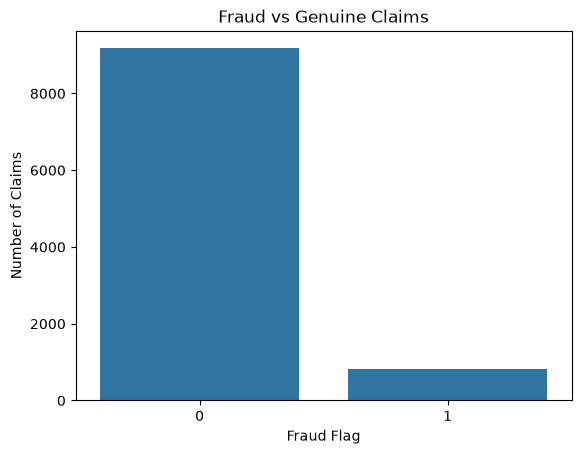

In [14]:
sns.countplot(data=data,x="Is_Fraud")
plt.title("Fraud vs Genuine Claims")
plt.xlabel("Fraud Flag")
plt.ylabel("Number of Claims")
plt.show()

**Explore Claim Amount**

In [15]:
data.groupby("Is_Fraud")["Claim_Amount"].mean()

Is_Fraud
0    535.008352
1    990.931797
Name: Claim_Amount, dtype: float64

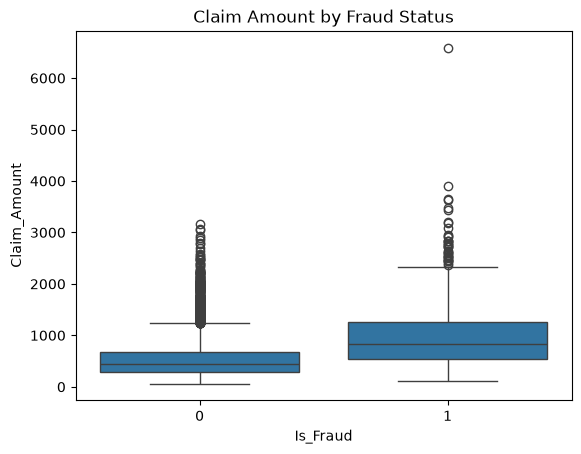

In [17]:
sns.boxplot(data=data,x="Is_Fraud", y="Claim_Amount")
plt.title("Claim Amount by Fraud Status")
plt.show()

**Explore approved amount**

In [19]:
data.groupby("Is_Fraud")["Approved_Amount"].mean()


Is_Fraud
0    469.154258
1    545.871978
Name: Approved_Amount, dtype: float64

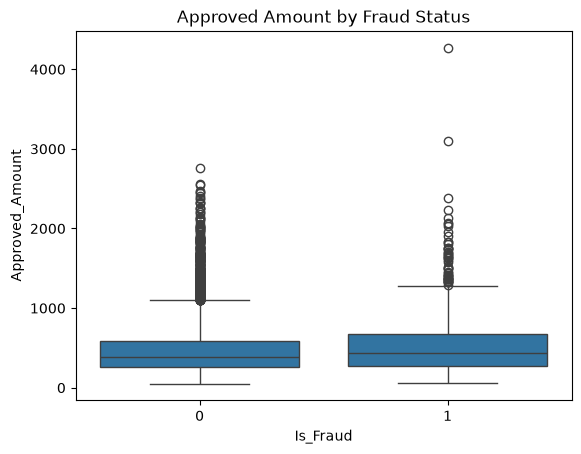

In [21]:
sns.boxplot(data=data,x="Is_Fraud",y="Approved_Amount")
plt.title("Approved Amount by Fraud Status")
plt.show()

**Feature Engineering**

Feature 1:

In [23]:
data["Approval_Ratio"]=(data["Approved_Amount"]/data["Claim_Amount"])

**Difference between claimed and approved**

In [24]:
data["Claim_Approval_Difference"]=(data["Claim_Amount"]-data["Approved_Amount"])

**Convert Date**

In [25]:
data["Claim_Submission_Date"]=pd.to_datetime(data["Claim_Submission_Date"])

**Extract year,month and dow(day of the week) from claim submission date**

In [26]:
data["Claim_Year"]=(data["Claim_Submission_Date"].dt.year)
data["Claim_Month"]=(data["Claim_Submission_Date"].dt.month)
data["Claim_DayOfWeek"]=(data["Claim_Submission_Date"].dt.dayofweek)

**Drop the columns that are not required**

In [27]:
data_model=data.drop(columns=["Claim_ID","Provider_ID","Claim_Submission_Date"])

**Separate X and Y**

In [28]:
X=data_model.drop(columns=["Is_Fraud"])
y=data_model["Is_Fraud"]

In [45]:
print("X_train shape:",X_train.shape)
print("y_train shape:",y_train.shape)
print("X_test shape:",X_test.shape)
print("y_test shape:",y_test.shape)

X_train shape: (8000, 21)
y_train shape: (2000, 21)
X_test shape: (8000,)
y_test shape: (2000,)


**Train/Test Split**

In [46]:
X_train,X_test,y_train,y_test= train_test_split(X,y,test_size=0.20,random_state=42, stratify=y)


**Identify categorical columns**

In [30]:
categorical_features=X.select_dtypes(include=["object"]).columns.tolist()
categorical_features

/var/folders/p6/kgyswtyx0cq6f97yf7b3tc500000gn/T/ipykernel_25306/1903999307.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_features=X.select_dtypes(include=["object"]).columns.tolist()


['Patient_Gender',
 'Diagnosis_Code',
 'Insurance_Type',
 'Provider_Specialty',
 'Patient_State',
 'Claim_Status',
 'Visit_Type']

**Identify numerical columns**

In [31]:
numerical_features=X.select_dtypes(include=["int64", "float64"]).columns.tolist()
numerical_features

['Patient_Age',
 'Procedure_Code',
 'Claim_Amount',
 'Approved_Amount',
 'Days_Between_Service_and_Claim',
 'Number_of_Claims_Per_Provider_Monthly',
 'Length_of_Stay',
 'Chronic_Condition_Flag',
 'Prior_Visits_12m',
 'Approval_Ratio',
 'Claim_Approval_Difference']

**Handle missing values and scaling**

In [33]:
numeric_transformer=Pipeline(steps=[("imputer",SimpleImputer(strategy="median")), ("scaler",StandardScaler())])

In [34]:
categorical_transformer=Pipeline(steps=[("imputer",SimpleImputer(strategy="most_frequent")),("onehot",OneHotEncoder(handle_unknown="ignore"))])

**Combine Preprocessing**

In [40]:
preprocessor= ColumnTransformer(transformers=[("num",numeric_transformer,numerical_features),("cat",categorical_transformer,categorical_features)])

**Logistic Regression**

In [41]:
logistic_model=Pipeline(steps=[("preprocessor",preprocessor),("classifier",LogisticRegression(max_iter=1000,class_weight="balanced"))])

In [47]:
logistic_model.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Patient_Age','Patient_Gender','Diagnosis_Code',...,'Claim_Year', 'Claim_Month','Claim_DayOfWeek']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

**Make predictions**

In [48]:
y_pred_lr=logistic_model.predict(X_test)

In [49]:
y_prob_lr=logistic_model.predict_proba(X_test)[:,1]

**Evaluate Logistic Regression**

In [50]:
print(classification_report(y_test,y_pred_lr))

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      1834
           1       0.86      0.98      0.92       166

    accuracy                           0.98      2000
   macro avg       0.93      0.98      0.95      2000
weighted avg       0.99      0.98      0.99      2000



In [51]:
print("ROC-AUC:",roc_auc_score(y_test,y_prob_lr))

ROC-AUC: 0.9991624075363613


**Confusion Matrix**

In [52]:
cm=confusion_matrix(y_test,y_pred_lr)
print(cm)

[[1807   27]
 [   3  163]]


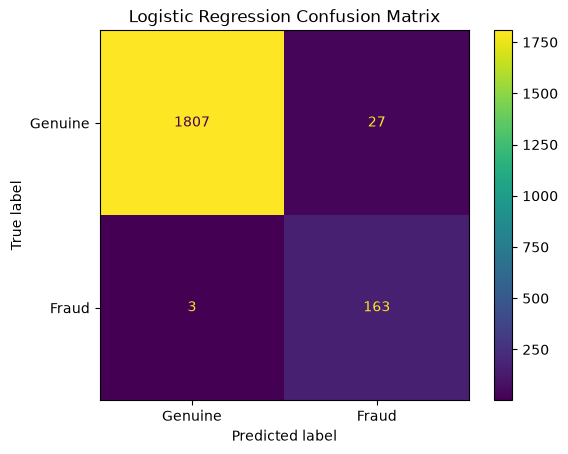

In [53]:
ConfusionMatrixDisplay(confusion_matrix=cm,display_labels=["Genuine","Fraud"]).plot()
plt.title("Logistic Regression Confusion Matrix")
plt.show()

**Random Forest**

In [54]:
random_forest=Pipeline(steps=[("preprocessor",preprocessor),("classifier",RandomForestClassifier(n_estimators=300,max_depth=10,random_state=42,class_weight="balanced",n_jobs=-1))])

In [55]:
random_forest.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('classifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](21,)","['Patient_Age','Patient_Gender','Diagnosis_Code',...,'Claim_Year', 'Claim_Month','Claim_DayOfWeek']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,21
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying 

In [56]:
y_pred_rf=random_forest.predict(X_test)

In [57]:
y_prob_rf=random_forest.predict_proba(X_test)[:,1]

**Evaluate Random Forest**

In [58]:
print(classification_report(y_test,y_pred_rf))

              precision    recall  f1-score   support

           0       1.00      1.00      1.00      1834
           1       0.95      0.96      0.95       166

    accuracy                           0.99      2000
   macro avg       0.97      0.98      0.98      2000
weighted avg       0.99      0.99      0.99      2000



In [59]:
rf_auc= roc_auc_score(y_test,y_prob_rf)
print("Random Forest ROC-AUC:", rf_auc)

Random Forest ROC-AUC: 0.9991755462416734


**Compare both models**


In [61]:
model_results = pd.DataFrame({

    "Model": [
        "Logistic Regression",
        "Random Forest"
    ],

    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_rf)
    ],

    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_rf)
    ],

    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_rf)
    ],

    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

model_results

,Model,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.857895,0.981928,0.915730,0.999162
1,Random Forest,0.952096,0.957831,0.954955,0.999176


**Get fraud probabilities**

In [62]:
fraud_probability = random_forest.predict_proba(
    X_test
)[:, 1]

In [63]:
results_df=X_test.copy()
results_df["Actual_Fraud"]=y_test.values
results_df["fraud_probability"]=fraud_probability

In [64]:
results_df.head()

,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m,Approval_Ratio,Claim_Approval_Difference,Claim_Year,Claim_Month,Claim_DayOfWeek,Actual_Fraud,fraud_probability
3811,25,Female,K21.9,99213,234.63,214.27,Self-Pay,18,73,Cardiology,GA,Approved,5,Outpatient,1,1.0,0.913225,20.36,2022,10,5,0,0.000411
5872,27,Male,N39.0,87086,501.94,493.35,Private,13,69,Cardiology,NY,Approved,1,Emergency,0,2.0,0.982886,8.59,2023,6,6,0,0.002649
895,34,Male,I10,93000,1018.97,490.73,Medicaid,0,92,General Practice,IL,Approved,5,Outpatient,0,3.0,0.481594,528.24,2024,11,3,1,0.959544
5410,95,Male,J18.9,71046,97.07,79.95,Medicare,26,61,Orthopedics,OH,Approved,3,Inpatient,0,3.0,0.823632,17.12,2022,10,5,0,0.004984
2362,78,Female,M54.5,97110,508.38,390.89,Medicare,14,65,General Practice,OH,Approved,2,Emergency,1,1.0,0.768893,117.49,2022,7,2,0,0.011465


**Create risk categories**

In [67]:
def risk_category(probability):
    if probability>=0.75:
        return "High Risk"
    elif probability>=0.4:
        return "Medium Risk"
    else:
        return "Low Risk"                

In [69]:
results_df["risk_category"]=(results_df["fraud_probability"].apply(risk_category))

**View High-Risk claims**

In [75]:
high_risk_claims= results_df[results_df["risk_category"]=="High Risk"]
high_risk_claims.head(20)

,Patient_Age,Patient_Gender,Diagnosis_Code,Procedure_Code,Claim_Amount,Approved_Amount,Insurance_Type,Days_Between_Service_and_Claim,Number_of_Claims_Per_Provider_Monthly,Provider_Specialty,Patient_State,Claim_Status,Length_of_Stay,Visit_Type,Chronic_Condition_Flag,Prior_Visits_12m,Approval_Ratio,Claim_Approval_Difference,Claim_Year,Claim_Month,Claim_DayOfWeek,Actual_Fraud,fraud_probability,risk_category
895,34,Male,I10,93000,1018.97,490.73,Medicaid,0,92,General Practice,IL,Approved,5,Outpatient,0,3.0,0.481594,528.24,2024,11,3,1,0.959544,High Risk
6047,42,Male,E11.9,80053,561.39,206.68,NaN,5,76,NaN,PA,Approved,0,Emergency,0,5.0,0.368158,354.71,2023,8,6,1,0.931856,High Risk
2610,51,Male,E11.9,80053,1397.02,779.27,Self-Pay,4,76,General Practice,NY,Pending,5,Inpatient,0,3.0,0.557809,617.75,2022,10,2,1,0.965664,High Risk
3575,60,Female,F41.9,99213,1776.86,1086.37,Self-Pay,4,99,General Practice,TX,Rejected,2,Emergency,1,6.0,0.611399,690.49,2023,12,5,1,0.959990,High Risk
1550,50,Female,I25.10,71046,944.21,678.35,Self-Pay,5,87,Cardiology,TX,Pending,2,Inpatient,0,3.0,0.718431,265.86,2023,6,4,1,0.956045,High Risk
7468,30,Male,I25.10,97110,1687.96,1251.01,Medicaid,1,62,Cardiology,NY,Approved,5,Outpatient,0,2.0,0.741137,436.95,2021,5,6,1,0.912917,High Risk
7595,68,Male,I10,93000,3188.11,1900.35,Self-Pay,1,59,Pulmonology,PA,Approved,0,Emergency,0,6.0,0.596074,1287.76,2022,3,3,1,0.929977,High Risk
8763,79,Female,K21.9,99213,387.02,255.60,Medicare,4,69,Orthopedics,IL,Rejected,3,Inpatient,0,5.0,0.660431,131.42,2021,12,5,1,0.891869,High Risk
3790,54,Male,N39.0,87086,849.48,302.36,Private,4,66,Pulmonology,TX,Rejected,1,Outpatient,1,2.0,0.355935,547.12,2024,10,6,1,0.989984,High Risk
1746,54,Male,I10,93000,2283.54,1165.27,Medicare,3,72,Cardiology,IL,Rejected,2,Outpatient,0,2.0,0.510291,1118.27,2023,5,4,1,0.983944,High Risk


**Save your Model**

In [76]:
joblib.dump(random_forest,"../models/fraud_model.pkl")

['../models/fraud_model.pkl']